In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

base = r"C:\Users\acer\OneDrive\Pictures\Camera Roll"

eagle_path = os.path.join(base, "Eagle_in_Flight.jpg")
apollo_path = os.path.join(base, "Apollo-11-launch.jpg")
boy_path = os.path.join(base, "boy.jpg")

In [2]:
img_gray = cv2.imread(eagle_path, cv2.IMREAD_GRAYSCALE)

if img_gray is None:
    raise FileNotFoundError("Eagle_in_Flight.jpg not found. Check the path.")

print("Image loaded successfully!")

Image loaded successfully!


In [3]:
height, width = img_gray.shape
channels = 1

print("Width:", width)
print("Height:", height)
print("Channel:", channels)

Width: 1536
Height: 1024
Channel: 1


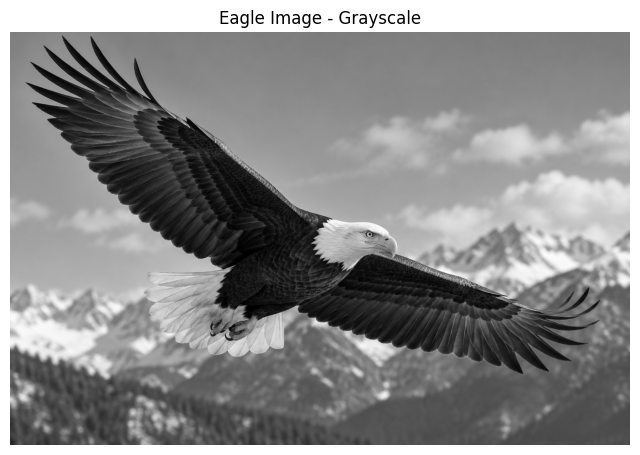

In [4]:
plt.figure(figsize=(8, 6))
plt.imshow(img_gray, cmap="gray")
plt.title("Eagle Image - Grayscale")
plt.axis("off")
plt.show()

In [5]:
cv2.imwrite(os.path.join(base, "Eagle_Grayscale.png"), img_gray)
print("Grayscale image saved successfully!")

Grayscale image saved successfully!


In [6]:
saved_gray = cv2.imread(
    os.path.join(base, "Eagle_Grayscale.png"),
    cv2.IMREAD_GRAYSCALE
)

img_color = cv2.cvtColor(saved_gray, cv2.COLOR_GRAY2BGR)
img_color_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

Width: 1536
Height: 1024
Channels: 3


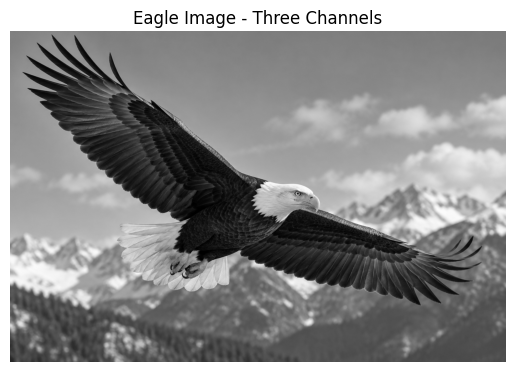

In [7]:
height, width, channels = img_color.shape

print("Width:", width)
print("Height:", height)
print("Channels:", channels)

plt.imshow(img_color_rgb)
plt.title("Eagle Image - Three Channels")
plt.axis("off")
plt.show()

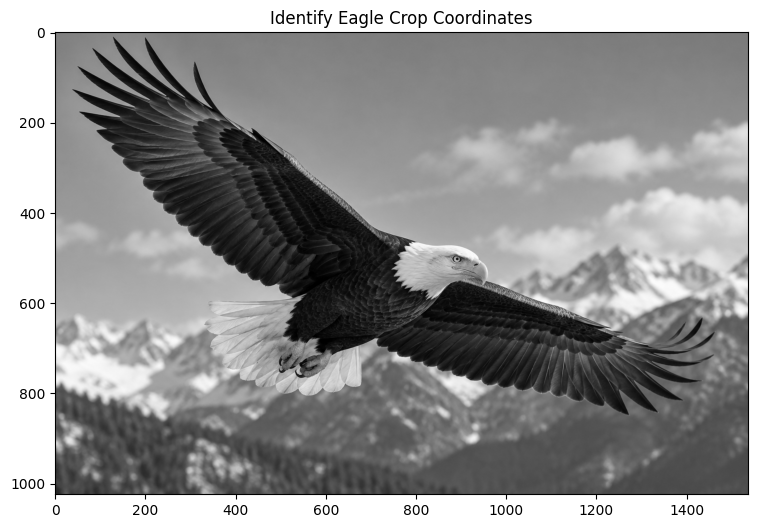

In [8]:
# Display image to identify crop coordinates
plt.figure(figsize=(10, 6))
plt.imshow(img_color_rgb)
plt.title("Identify Eagle Crop Coordinates")
plt.axis("on")
plt.show()

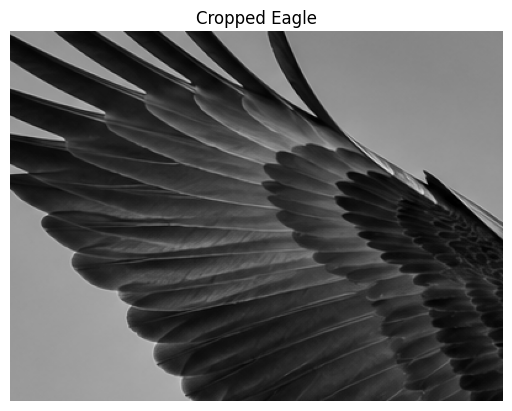

In [9]:
# Replace these example coordinates after inspecting the image
x1, y1 = 100, 100
x2, y2 = 500, 400

eagle_crop = img_color[y1:y2, x1:x2]
eagle_crop_rgb = cv2.cvtColor(eagle_crop, cv2.COLOR_BGR2RGB)

plt.imshow(eagle_crop_rgb)
plt.title("Cropped Eagle")
plt.axis("off")
plt.show()

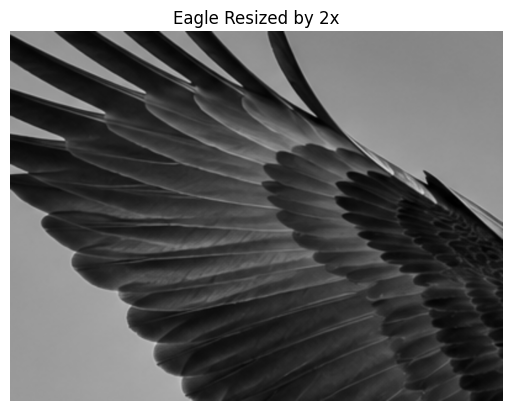

In [10]:
eagle_resized = cv2.resize(
    eagle_crop,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_LINEAR
)

plt.imshow(cv2.cvtColor(eagle_resized, cv2.COLOR_BGR2RGB))
plt.title("Eagle Resized by 2x")
plt.axis("off")
plt.show()

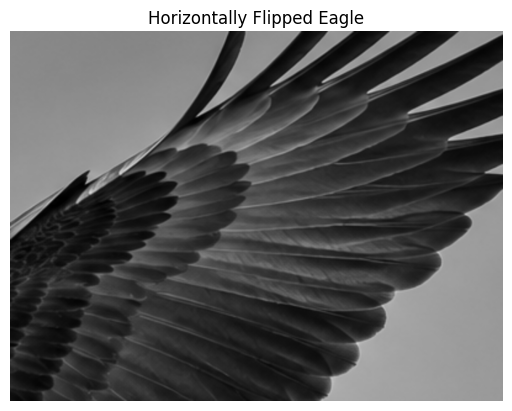

In [11]:
eagle_flipped = cv2.flip(eagle_resized, 1)

plt.imshow(cv2.cvtColor(eagle_flipped, cv2.COLOR_BGR2RGB))
plt.title("Horizontally Flipped Eagle")
plt.axis("off")
plt.show()

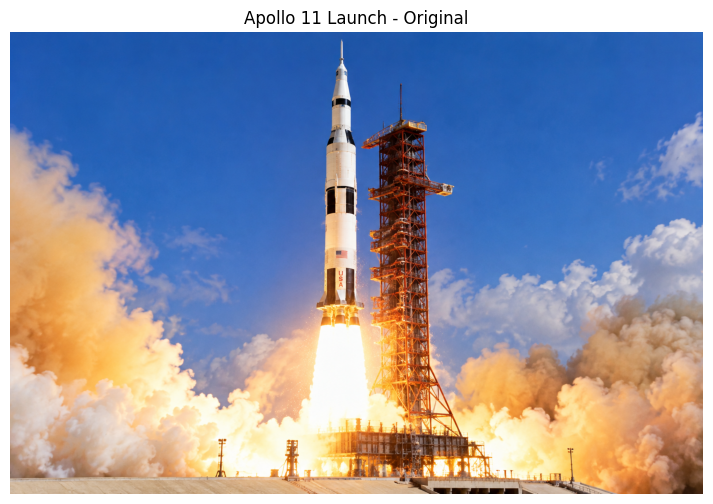

Image dimensions: (1024, 1536, 3)


In [12]:
apollo = cv2.imread(apollo_path)

if apollo is None:
    raise FileNotFoundError("Apollo-11-launch.jpg not found. Check the path.")

apollo_rgb = cv2.cvtColor(apollo, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(9, 6))
plt.imshow(apollo_rgb)
plt.title("Apollo 11 Launch - Original")
plt.axis("off")
plt.show()

print("Image dimensions:", apollo.shape)

In [13]:
text = "Apollo 11 Saturn V Launch, July 16, 1969"
font_face = cv2.FONT_HERSHEY_PLAIN

h, w = apollo.shape[:2]
font_scale = max(1, w / 1000)
thickness = 2

text_size = cv2.getTextSize(
    text, font_face, font_scale, thickness
)[0]

text_x = (w - text_size[0]) // 2
text_y = h - 20

cv2.putText(
    apollo, text, (text_x, text_y),
    font_face, font_scale, (255, 255, 255),
    thickness, cv2.LINE_AA
)

array([[[161,  86,  34],
        [172,  87,  32],
        [171,  86,  31],
        ...,
        [186, 103,  44],
        [187, 104,  45],
        [177, 104,  47]],

       [[169,  86,  30],
        [176,  85,  30],
        [176,  87,  32],
        ...,
        [188, 101,  42],
        [190, 101,  42],
        [182, 102,  43]],

       [[171,  87,  31],
        [176,  86,  30],
        [176,  88,  32],
        ...,
        [187, 101,  42],
        [189, 101,  42],
        [185, 103,  44]],

       ...,

       [[159, 182, 207],
        [157, 181, 206],
        [156, 182, 207],
        ...,
        [ 17,  37,  67],
        [ 17,  38,  68],
        [ 18,  39,  69]],

       [[158, 184, 208],
        [156, 181, 206],
        [155, 181, 206],
        ...,
        [ 18,  38,  69],
        [ 18,  37,  68],
        [ 18,  38,  68]],

       [[157, 179, 203],
        [156, 181, 205],
        [155, 181, 205],
        ...,
        [ 19,  39,  70],
        [ 19,  39,  68],
        [ 20,  41,  67]]

In [14]:
# Example coordinates; change them to fit your image
x1, y1 = 100, 50
x2, y2 = apollo.shape[1] - 100, apollo.shape[0] - 50

magenta = (255, 0, 255)  # BGR format

cv2.rectangle(
    apollo, (x1, y1), (x2, y2),
    magenta, 3
)

array([[[161,  86,  34],
        [172,  87,  32],
        [171,  86,  31],
        ...,
        [186, 103,  44],
        [187, 104,  45],
        [177, 104,  47]],

       [[169,  86,  30],
        [176,  85,  30],
        [176,  87,  32],
        ...,
        [188, 101,  42],
        [190, 101,  42],
        [182, 102,  43]],

       [[171,  87,  31],
        [176,  86,  30],
        [176,  88,  32],
        ...,
        [187, 101,  42],
        [189, 101,  42],
        [185, 103,  44]],

       ...,

       [[159, 182, 207],
        [157, 181, 206],
        [156, 182, 207],
        ...,
        [ 17,  37,  67],
        [ 17,  38,  68],
        [ 18,  39,  69]],

       [[158, 184, 208],
        [156, 181, 206],
        [155, 181, 206],
        ...,
        [ 18,  38,  69],
        [ 18,  37,  68],
        [ 18,  38,  68]],

       [[157, 179, 203],
        [156, 181, 205],
        [155, 181, 205],
        ...,
        [ 19,  39,  70],
        [ 19,  39,  68],
        [ 20,  41,  67]]

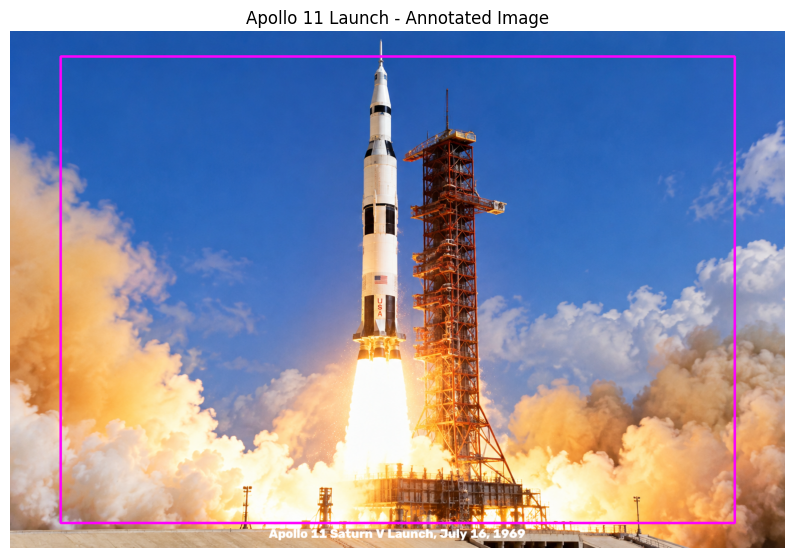

True

In [15]:
apollo_final_rgb = cv2.cvtColor(apollo, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(apollo_final_rgb)
plt.title("Apollo 11 Launch - Annotated Image")
plt.axis("off")
plt.show()

cv2.imwrite(os.path.join(base, "Apollo_Annotated.jpg"), apollo)

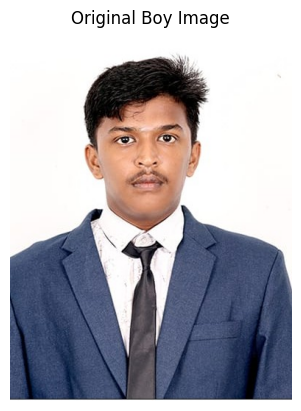

In [16]:
img = cv2.imread(boy_path)

if img is None:
    raise FileNotFoundError("boy.jpg not found. Check the path.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Boy Image")
plt.axis("off")
plt.show()

In [17]:
# Create a matrix of ones with float64 data type
matrix_ones = np.ones(img.shape, dtype=np.float64)

# Convert to the image's data type for OpenCV arithmetic
matrix = matrix_ones.astype(img.dtype)

img_brighter = cv2.add(img, matrix)
img_darker = cv2.subtract(img, matrix)

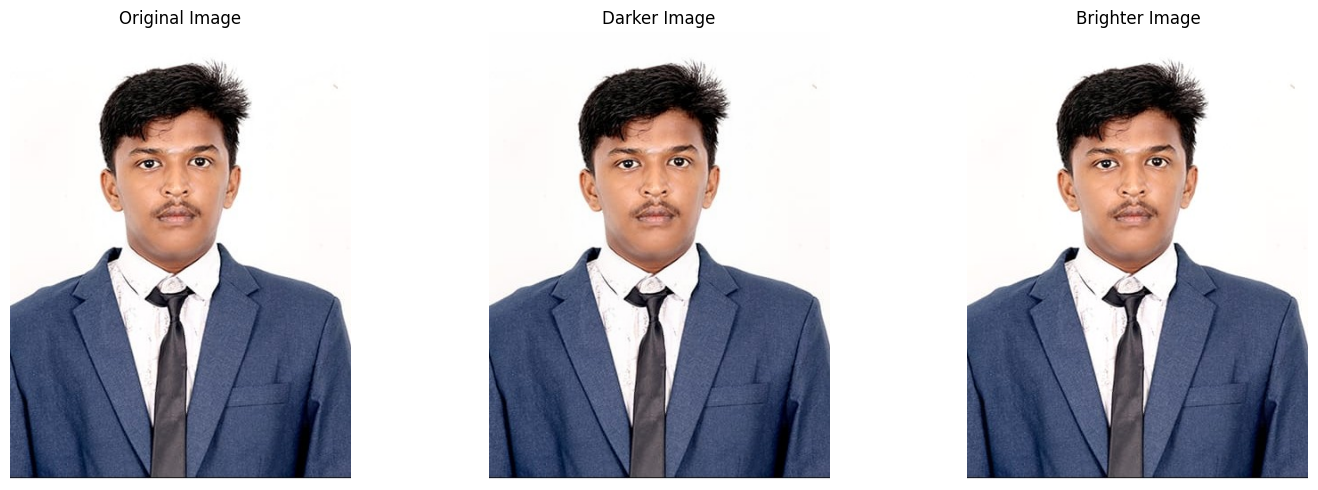

In [18]:
images = [img, img_darker, img_brighter]
titles = ["Original Image", "Darker Image", "Brighter Image"]

plt.figure(figsize=(15, 5))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Lower contrast
matrix_low = np.ones(img.shape, dtype=np.float64) * 0.8
img_lower = (img.astype(np.float64) * matrix_low).astype(np.uint8)

# Higher contrast using factors 1.1 and 1.2
matrix1 = np.ones(img.shape, dtype=np.float64) * 1.1
matrix2 = np.ones(img.shape, dtype=np.float64) * 1.2

img_higher1 = (img.astype(np.float64) * matrix1).astype(np.uint8)
img_higher2 = (img.astype(np.float64) * matrix2).astype(np.uint8)

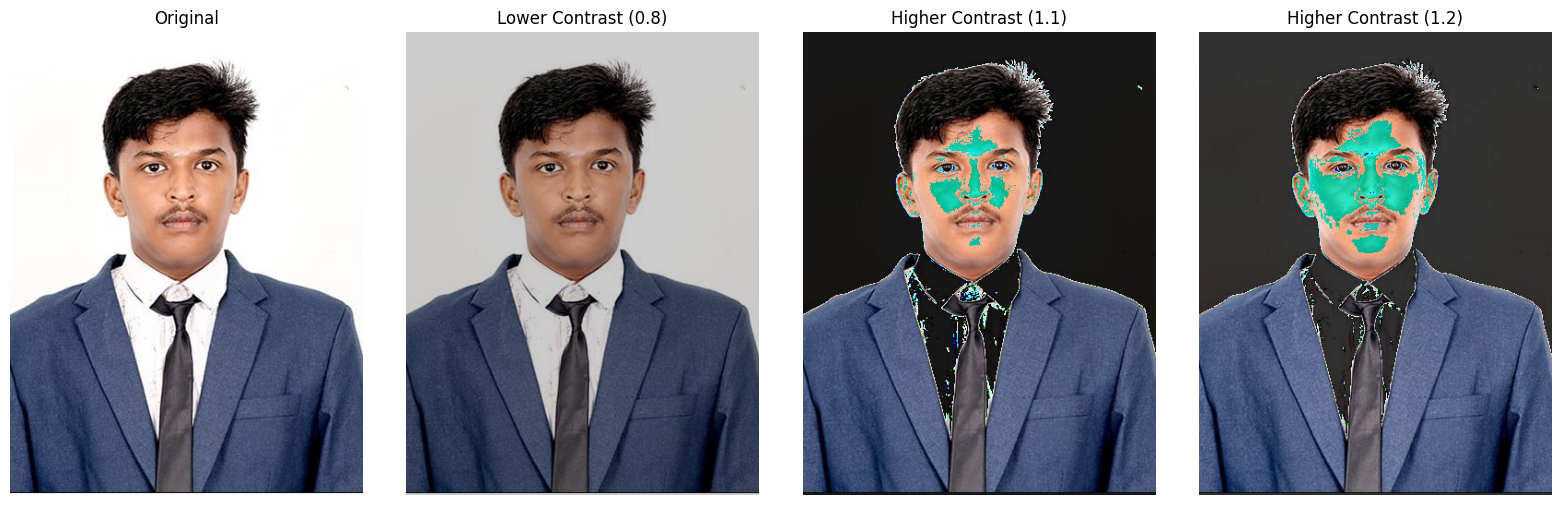

In [20]:
images = [img, img_lower, img_higher1, img_higher2]
titles = [
    "Original",
    "Lower Contrast (0.8)",
    "Higher Contrast (1.1)",
    "Higher Contrast (1.2)"
]

plt.figure(figsize=(16, 5))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

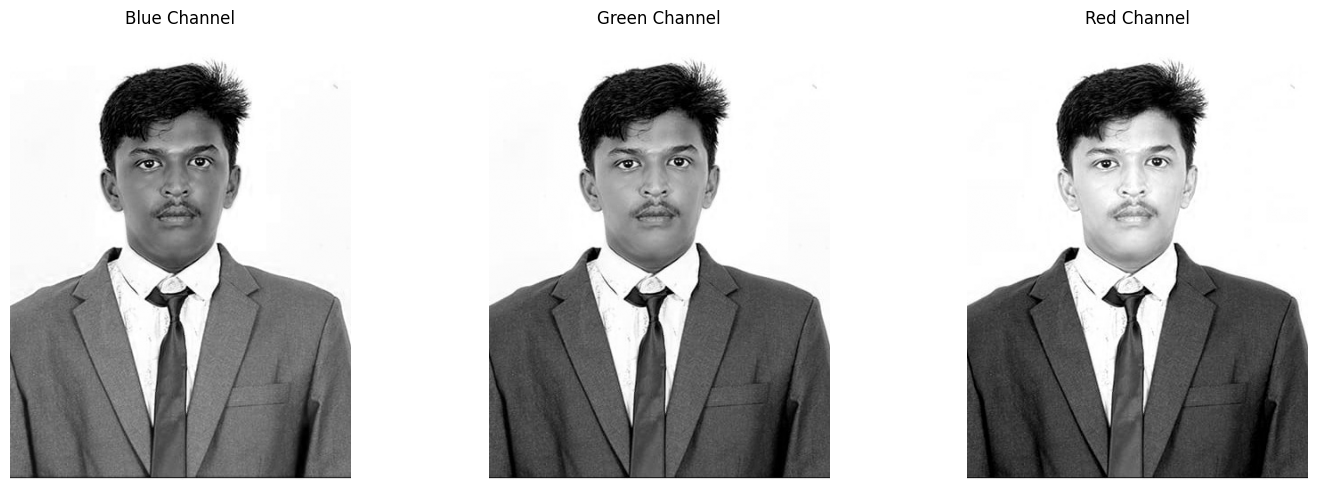

In [21]:
B, G, R = cv2.split(img)

plt.figure(figsize=(15, 5))

for i, (channel, title) in enumerate([
    (B, "Blue Channel"),
    (G, "Green Channel"),
    (R, "Red Channel")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channel, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

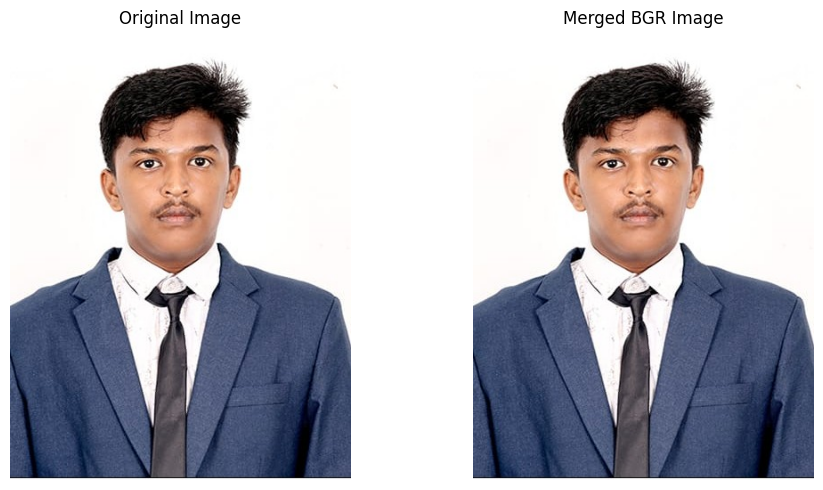

In [22]:
merged_bgr = cv2.merge([B, G, R])
merged_rgb = cv2.cvtColor(merged_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(merged_rgb)
plt.title("Merged BGR Image")
plt.axis("off")

plt.tight_layout()
plt.show()

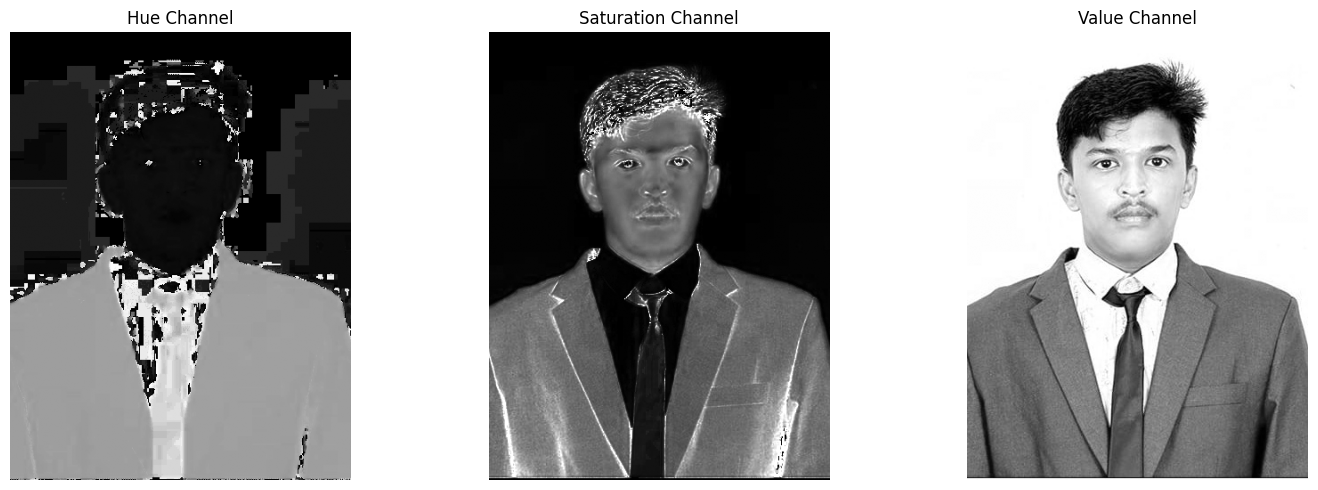

In [23]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv)

plt.figure(figsize=(15, 5))

for i, (channel, title) in enumerate([
    (H, "Hue Channel"),
    (S, "Saturation Channel"),
    (V, "Value Channel")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channel, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

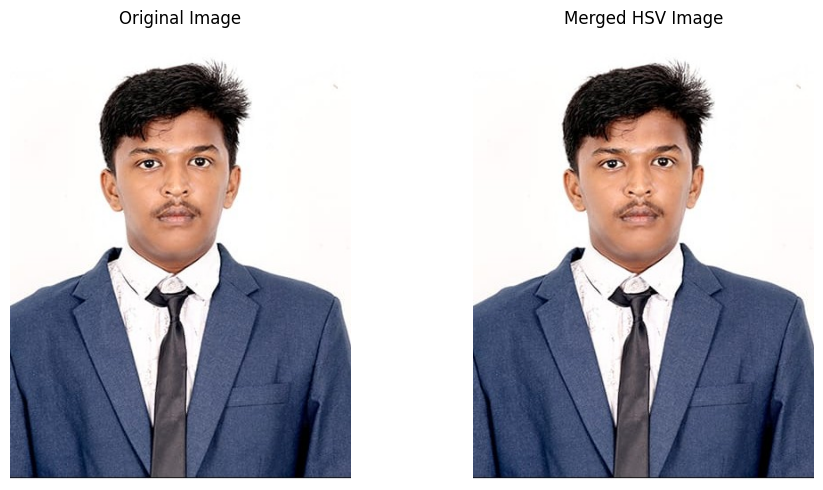

In [24]:
merged_hsv = cv2.merge([H, S, V])
merged_bgr_hsv = cv2.cvtColor(merged_hsv, cv2.COLOR_HSV2BGR)
merged_hsv_rgb = cv2.cvtColor(merged_bgr_hsv, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(merged_hsv_rgb)
plt.title("Merged HSV Image")
plt.axis("off")

plt.tight_layout()
plt.show()